Upload your used_car_dataset.csv now:


Saving used_cars_dataset.csv to used_cars_dataset (2).csv
Loaded: used_cars_dataset (2).csv


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,NaN,NaN,2001.0,23.0,"98,000 km",NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,NaN,NaN,15.0,190000.0 km,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,NaN,2010.0,NaN,NaN,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,NaN,Swift,2017.0,7.0,NaN,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,NaN,2019.0,5.0,NaN,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


Columns: ['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice']
Price column detected: AskPrice
Cleaned price, remaining rows: 24575
Brand            5269
model           10431
Year             5179
Age              5975
kmDriven            0
Transmission     5922
Owner           10626
FuelType         5239
PostedDate       6220
AdditionInfo        0
AskPrice            0
dtype: int64


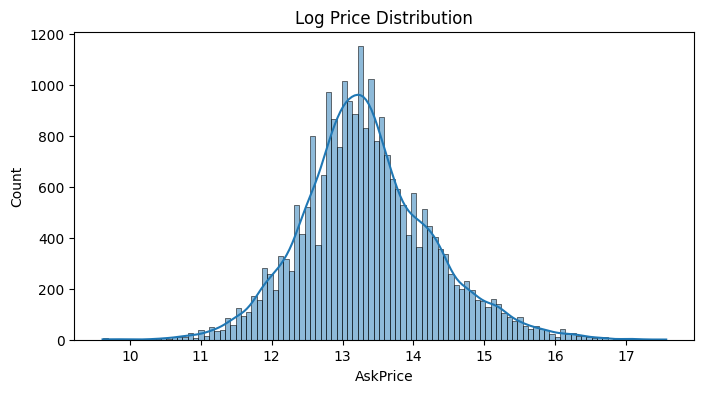

Using features: ['Brand', 'model', 'FuelType', 'Transmission', 'Owner', 'Year', 'Age', 'kmDriven', 'Post_Month', 'info_len']
=== RESULTS ===
MAE: R 251,201
RMSE: R 630,483
R2 Score: 0.810 (1.0 is perfect)


In [3]:
!pip install xgboost -q
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import re

print("Upload your used_car_dataset.csv now:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))
print(f"Loaded: {filename}")
display(df.head())

df.columns = [c.strip() for c in df.columns]
print("Columns:", df.columns.tolist())

price_col = [c for c in df.columns if 'price' in c.lower()][0]
print(f"Price column detected: {price_col}")

df[price_col] = df[price_col].astype(str)
df[price_col] = df[price_col].str.replace(r'[₹,₹ ]', '', regex=True)
df[price_col] = df[price_col].str.extract(r'(\d+)')[0]
df[price_col] = pd.to_numeric(df[price_col], errors='coerce')
df = df.dropna(subset=[price_col])
df = df[df[price_col] > 10000]
print(f"Cleaned price, remaining rows: {len(df)}")

if 'kmDriven' in df.columns:
    df['kmDriven'] = df['kmDriven'].astype(str).str.replace(r'[^0-9]', '', regex=True)
    df['kmDriven'] = pd.to_numeric(df['kmDriven'], errors='coerce')
    df['kmDriven'] = df['kmDriven'].fillna(df['kmDriven'].median())
    df['kmDriven'] = df['kmDriven'].clip(upper=df['kmDriven'].quantile(0.99))

print(df.isnull().sum())
plt.figure(figsize=(8,4))
sns.histplot(np.log1p(df[price_col]), kde=True)
plt.title("Log Price Distribution")
plt.show()

if 'PostedDate' in df.columns:
    df['PostedDate'] = pd.to_datetime(df['PostedDate'], format='%b-%y', errors='coerce')
    df['Post_Month'] = df['PostedDate'].dt.month.fillna(6)

if 'AdditionInfo' in df.columns:
    df['AdditionInfo'] = df['AdditionInfo'].fillna('')
    df['info_len'] = df['AdditionInfo'].str.len()
else:
    df['info_len'] = 0
    df['Post_Month'] = 1

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Age'] = df['Age'].fillna(2026 - df['Year'])
df['Year'] = df['Year'].fillna(2026 - df['Age'])
df = df.dropna(subset=['Year','Age'])

for c in ['Brand','model','FuelType','Transmission','Owner']:
    if c in df.columns:
        df[c] = df[c].fillna('Unknown').astype(str)

cat_cols = [c for c in ['Brand','model','FuelType','Transmission','Owner'] if c in df.columns]
num_cols = [c for c in ['Year','Age','kmDriven','Post_Month','info_len'] if c in df.columns]

X = df[cat_cols + num_cols]
y = df[price_col]

print(f"Using features: {cat_cols + num_cols}")

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), cat_cols),
    ('num', StandardScaler(), num_cols)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipe = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))
])

pipe.fit(X_train, y_train)
pred = pipe.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print(f"=== RESULTS ===")
print(f"MAE: R {mae:,.0f}")
print(f"RMSE: R {rmse:,.0f}")
print(f"R2 Score: {r2:.3f} (1.0 is perfect)")